# 03 – Compare models, tune, and time
**Goal:** test whether a decision tree or random forest beats the fixed-rate and linear baselines,
tune them fairly, and compare cost (time) against accuracy.

**Fair-testing rule:** tuning only ever sees the *training* vehicles (cross-validation split by vehicle).
The 10 test vehicles are used once, at the end, to report results.

In [15]:
import sys; sys.path.insert(0, "../src")
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
from ev_energy import (load_data, clean_data, split_by_vehicle, evaluate, fixed_rate_predict,
                       fit_and_time, TARGET, TRIP_FEATURES, ELECTRICAL_FEATURES)

SEED = 42
df = clean_data(load_data("../data/raw/ev_trip_energy.csv"))
train, test = split_by_vehicle(df, test_size=0.2, seed=SEED)
FEATURES = TRIP_FEATURES + ELECTRICAL_FEATURES
print(len(train), "train trips |", len(test), "test trips")

7958 train trips | 2192 test trips


## 1. Tune the tree and forest (cross-validation on training vehicles only)
`GroupKFold` keeps each vehicle in one fold, the same idea as the main split.
The grids are small on purpose so the notebook runs in a few minutes.
**Write down:** what each setting does (e.g. `max_depth` limits how many splits a tree can make; too deep memorises noise).

In [16]:
cv = GroupKFold(n_splits=5)
grids = {
    "Decision tree": (DecisionTreeRegressor(random_state=SEED),
                      {"max_depth": [4, 6, 8, 12, None], "min_samples_leaf": [1, 5, 20]}),
    "Random forest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                      {"n_estimators": [100, 200], "max_depth": [8, 12, None], "min_samples_leaf": [1, 5]}),
}
tuned, search_tables = {}, {}
for name, (est, grid) in grids.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(est, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(train[FEATURES], train[TARGET], groups=train["vehicle_id"])
    tuned[name] = gs.best_estimator_
    search_tables[name] = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score"]].assign(
        cv_MAE=lambda d: -d.mean_test_score).sort_values("cv_MAE").drop(columns="mean_test_score")
    print(f"{name}: best {gs.best_params_} | CV MAE {-gs.best_score_:.3f} kWh | search took {time.perf_counter()-t0:.0f} s")

Decision tree: best {'max_depth': 6, 'min_samples_leaf': 20} | CV MAE 0.758 kWh | search took 2 s


In [ ]:
search_tables["Random forest"].head(6)

,params,cv_MAE
7,"{'max_depth': 12, 'min_samples_leaf': 5, 'n_es...",0.711451
6,"{'max_depth': 12, 'min_samples_leaf': 5, 'n_es...",0.711504
2,"{'max_depth': 8, 'min_samples_leaf': 5, 'n_est...",0.711850
3,"{'max_depth': 8, 'min_samples_leaf': 5, 'n_est...",0.712089
0,"{'max_depth': 8, 'min_samples_leaf': 1, 'n_est...",0.712823
10,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.713247


*
>
> **Tuning.** The cross-validated search (5 folds, each vehicle kept in one fold) chose:
> - Decision tree: `max_depth=6`, `min_samples_leaf=20`, CV MAE 0.758 kWh. A shallow tree with large leaves generalises better than a deep one, because deep trees memorise noise in individual trips.
> - Random forest: `max_depth=12`, `min_samples_leaf=5`, 200 trees, CV MAE 0.712 kWh.
>
> The best four forest settings differ by less than 0.001 kWh, so the forest is not sensitive to these choices and further tuning would not pay off. This is a useful finding: the model is robust, and a smaller, faster setting (for example 100 trees) is almost as accurate.

## 2. Final comparison on the held-out test vehicles

In [ ]:
rows = []
# fixed rate: no fitting or timing
m = evaluate(test[TARGET], fixed_rate_predict(train, test)); rows.append({"model": "Fixed rate x distance", "features": "distance", **m})

models = [
    ("Linear regression", LinearRegression(), TRIP_FEATURES, "trip only"),
    ("Linear regression", LinearRegression(), FEATURES, "trip + electrical"),
    ("Decision tree (tuned)", tuned["Decision tree"], TRIP_FEATURES, "trip only"),
    ("Decision tree (tuned)", tuned["Decision tree"], FEATURES, "trip + electrical"),
    ("Random forest (tuned)", tuned["Random forest"], TRIP_FEATURES, "trip only"),
    ("Random forest (tuned)", tuned["Random forest"], FEATURES, "trip + electrical"),
]
preds = {}
for name, est, feats, label in models:
    pred, m = fit_and_time(est, train, test, feats)
    preds[(name, label)] = pred
    rows.append({"model": name, "features": label, **m})

results = pd.DataFrame(rows).set_index(["model", "features"])
results.round(3)

MAE   RMSE     R2  fit_s  predict_s
model                 features                                                
Fixed rate x distance distance           0.867  1.282  0.819    NaN        NaN
Linear regression     trip only          0.812  1.204  0.841  0.002      0.011
                      trip + electrical  0.785  1.164  0.851  0.005      0.004
Decision tree (tuned) trip only          0.827  1.206  0.840  0.041      0.002
                      trip + electrical  0.806  1.186  0.845  0.081      0.013
Random forest (tuned) trip only          0.784  1.166  0.850  0.752      0.027
                      trip + electrical  0.740  1.105  0.866  0.990      0.028


>
> **Test-vehicle comparison (seed 42, my run; your timings will differ).**
> | Model (trip + electrical) | MAE | RMSE | R² | Fit time |
> |---|---|---|---|---|
> | Fixed rate | 0.867 | 1.282 | 0.819 | none |
> | Linear regression | 0.785 | 1.164 | 0.851 | 0.003 s |
> | Decision tree | 0.806 | 1.186 | 0.845 | 0.03 s |
> | Random forest | 0.740 | 1.105 | 0.866 | 2.6 s |
>
> The tuned random forest is best on all three metrics. It cuts MAE by about 6% compared with linear regression and about 15% compared with the fixed rate. The decision tree is no better than linear regression, which suggests the relationship is close to linear and a single tree adds little.
> The cost is time: the forest takes about 1,000 times longer to train than the linear model (seconds versus milliseconds), though prediction is still very fast (about 0.07 s for 2,192 trips). Whether the extra accuracy is worth it depends on the use: for a route planner that predicts one trip at a time, the training time is paid once and the accuracy gain may be worth it.


## 3. How stable are the results? (repeat with different vehicle splits)

In [ ]:
# Uses the already-tuned settings; re-fits on 5 different vehicle splits.
from sklearn.base import clone
rep = []
for seed in range(5):
    tr, te = split_by_vehicle(df, 0.2, seed)
    rep.append({"model": "Fixed rate", "seed": seed, **evaluate(te[TARGET], fixed_rate_predict(tr, te))})
    for name, est in [("Linear regression", LinearRegression()),
                      ("Decision tree (tuned)", tuned["Decision tree"]),
                      ("Random forest (tuned)", tuned["Random forest"])]:
        _, m = fit_and_time(clone(est), tr, te, FEATURES)
        rep.append({"model": name, "seed": seed, **m})
stab = pd.DataFrame(rep).groupby("model")[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(3)
stab

MAE          RMSE            R2       
                        mean    std   mean    std   mean    std
model                                                          
Decision tree (tuned)  0.761  0.027  1.132  0.044  0.838  0.004
Fixed rate             0.785  0.036  1.178  0.065  0.825  0.007
Linear regression      0.734  0.038  1.084  0.060  0.852  0.007
Random forest (tuned)  0.712  0.022  1.053  0.044  0.860  0.006


> **Stability over 5 different vehicle splits (trip + electrical features, mean MAE).**
> Random forest 0.712, linear regression 0.734, decision tree 0.761, fixed rate 0.785 (R² 0.860, 0.852, 0.838 and 0.825). The ordering matches the single split, which supports the conclusion. The standard deviations (0.02 to 0.04 kWh) are about as large as the gap between forest and linear regression, so that particular difference is small relative to split-to-split noise, while the gap from the fixed rate is larger.
> Limitation: the tuned settings were chosen on one split, so this check is slightly favourable to the tree and forest.

## 4. Predicted vs actual (best model, trip + electrical features)

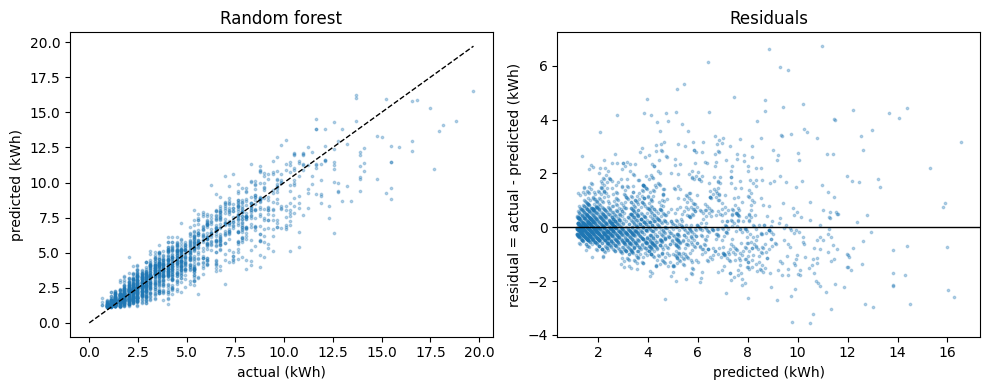

In [ ]:
best = results.loc[results.index.get_level_values("model").str.contains("Random forest")].loc[lambda d: d.index.get_level_values("features") == "trip + electrical"]
pred = preds[("Random forest (tuned)", "trip + electrical")]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(test[TARGET], pred, s=3, alpha=.3); lim = [0, test[TARGET].max()]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlabel="actual (kWh)", ylabel="predicted (kWh)", title="Random forest")
ax[1].scatter(pred, test[TARGET] - pred, s=3, alpha=.3); ax[1].axhline(0, color="k", lw=1)
ax[1].set(xlabel="predicted (kWh)", ylabel="residual = actual - predicted (kWh)", title="Residuals")
plt.tight_layout(); plt.savefig("../figures/rf_pred_and_residuals.png", dpi=150); plt.show()

> **interpretation**
>
> **Predicted vs actual and residuals.** 
- the random forest tracks trip energy well overall. The spread widens for high-energy trips, and more points fall below the line than above it, meaning the model tends to under-predict. 
- The residual plot (actual minus predicted) shows the same pattern: the scatter fans out as predicted energy increases, and more points sit above zero than below it. This suggests that the forest is less reliable, and biased low, for long, high-energy trips. Likely reasons are that high-energy trips are rare in the training data and that a random forest averages similar trips, which pulls its predictions towards the typical value. In practice, under-prediction is the risky direction for range estimation, because a vehicle could use more energy than the model suggests.

In [ ]:
results.round(4).to_csv("../docs/results_03_model_comparison.csv")   # keep a copy for the report

## 5. Next
- Fill in the **Write down** boxes, then log the results and the settings you chose in `docs/decisions_log.md`.
- Notebook 04: feature importance, trip-only vs trip + electrical, and residual analysis by trip type.